<a href="https://colab.research.google.com/github/Luci893/analisis-probabilidad-estadistica/blob/main/Analisis_Probabilidad_Estadistica_TLuciana.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introducción a la Probabilidad y Estadística

#### Tareas pendientes (TODO):
1. **Estadística Descriptiva:**
    * Calcular estadísticas como Moda, Media, Mediana y Desviación Estándar del peso y la edad. ¿Se ajustan a alguna distribución conocida?
    * Realizar un análisis de valores atípicos (outliers) y valores faltantes.
    * Explicar cómo varían las métricas al desglosar el conjunto de datos por género. ¿Se ajustan a alguna distribución conocida? Comparar cualitativa y gráficamente ambas distribuciones.
2. Calcular la probabilidad marginal y conjunta, y la correlación entre otras dos variables, por ejemplo, el consumo de alcohol y el tabaquismo.
    * Representar visualmente la probabilidad conjunta entre los posibles valores de las variables elegidas.
3. Responder a las siguientes preguntas: ¿Qué pasaría con los niveles de tabaquismo si se prohibiera fumar en los bares? ¿Qué pasaría con el número de consumidores de alcohol si disminuye el número de fumadores que consumen alcohol?

In [2]:
import copy
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme()

import warnings
warnings.filterwarnings("ignore")

In [3]:
young = pd.read_csv('https://raw.githubusercontent.com/anyoneai/notebooks/main/datasets/people_responses.csv')

In [4]:
young.head(5)

,Music,Slow songs or fast songs,Dance,Folk,Country,Classical music,Musical,Pop,Rock,Metal or Hardrock,...,Age,Height,Weight,Number of siblings,Gender,Left - right handed,Education,Only child,Village - town,House - block of flats
0,5.0,3.0,2.0,1.0,2.0,2.0,1.0,5.0,5.0,1.0,...,20.0,163.0,48.0,1.0,female,right handed,college/bachelor degree,no,village,block of flats
1,4.0,4.0,2.0,1.0,1.0,1.0,2.0,3.0,5.0,4.0,...,19.0,163.0,58.0,2.0,female,right handed,college/bachelor degree,no,city,block of flats
2,5.0,5.0,2.0,2.0,3.0,4.0,5.0,3.0,5.0,3.0,...,20.0,176.0,67.0,2.0,female,right handed,secondary school,no,city,block of flats
3,5.0,3.0,2.0,1.0,1.0,1.0,1.0,2.0,2.0,1.0,...,22.0,172.0,59.0,1.0,female,right handed,college/bachelor degree,yes,city,house/bungalow
4,5.0,3.0,4.0,3.0,2.0,4.0,3.0,5.0,3.0,1.0,...,20.0,170.0,59.0,1.0,female,right handed,secondary school,no,village,house/bungalow


*****
## 1. Estadística Descriptiva

In [5]:
print('Estadísticas Descriptivas para Edad y Peso:')
print('-------------------------------------')
display(young[['Age', 'Weight']].describe())

print('\nModa para Edad:')
display(young['Age'].mode().to_frame())

print('\nModa para Peso:')
display(young['Weight'].mode().to_frame())

Descriptive Statistics for Age and Weight:
-------------------------------------


,Age,Weight
count,1003.000000,990.000000
mean,20.433699,66.405051
std,2.828840,13.839561
min,15.000000,41.000000
25%,19.000000,55.000000
50%,20.000000,64.000000
75%,22.000000,75.000000
max,30.000000,165.000000



Mode for Age:


,Age
0,19.0



Mode for Weight:


,Weight
0,60.0


### Distribución de Frecuencia por Edad y Peso

In [7]:
print('Distribución de Frecuencia por Año:')
display(young['Age'].value_counts().sort_index().to_frame())

print('\nDistribución de Frecuencia por Peso:')
display(young['Weight'].value_counts().sort_index().to_frame())

Distribución de Frecuencia por Año:


,count
Age,
15.0,11
16.0,29
17.0,53
18.0,123
19.0,210
20.0,194
21.0,127
22.0,84
23.0,47



Distribución de Frecuencia por Peso:


,count
Weight,
41.0,1
42.0,1
43.0,2
44.0,3
45.0,5
...,...
113.0,1
120.0,3
125.0,1


### Histogramas

Histogramas de Edad y Peso:


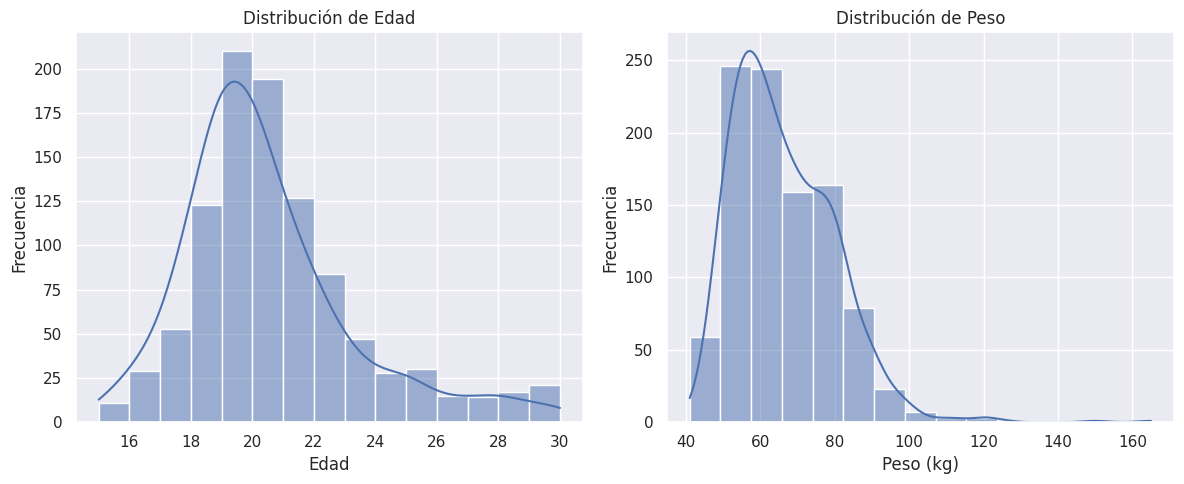

In [8]:
print('Histogramas de Edad y Peso:')

# Histograma para la edad
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(young['Age'].dropna(), kde=True, bins=15)
plt.title('Distribución de Edad')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')

# Histograma para el peso
plt.subplot(1, 2, 2)
sns.histplot(young['Weight'].dropna(), kde=True, bins=15)
plt.title('Distribución de Peso')
plt.xlabel('Peso (kg)')
plt.ylabel('Frecuencia')

plt.tight_layout()
plt.show()

### Valores Faltantes

In [10]:
print('Análisis de Valores Faltantes:')

# Contar valores faltantes por columna
missing_values = young.isnull().sum()

# Filtrar solo las columnas con valores faltantes
missing_values = missing_values[missing_values > 0]

display(missing_values.to_frame(name='Valores Faltantes'))

# Calcular el porcentaje de valores faltantes
missing_percentage = (young.isnull().sum() / len(young)) * 100
missing_percentage = missing_percentage[missing_percentage > 0]
display(missing_percentage.to_frame(name='Porcentaje Faltante'))

Análisis de Valores Faltantes:


,Valores Faltantes
Music,3
Slow songs or fast songs,2
Dance,4
Folk,5
Country,5
...,...
Left - right handed,3
Education,1
Only child,2
Village - town,4


,Porcentaje Faltante
Music,0.29703
Slow songs or fast songs,0.19802
Dance,0.39604
Folk,0.49505
Country,0.49505
...,...
Left - right handed,0.29703
Education,0.09901
Only child,0.19802
Village - town,0.39604


### Valores Atípicos (Outliers)

Identificación de Outliers (Valores Atípicos):


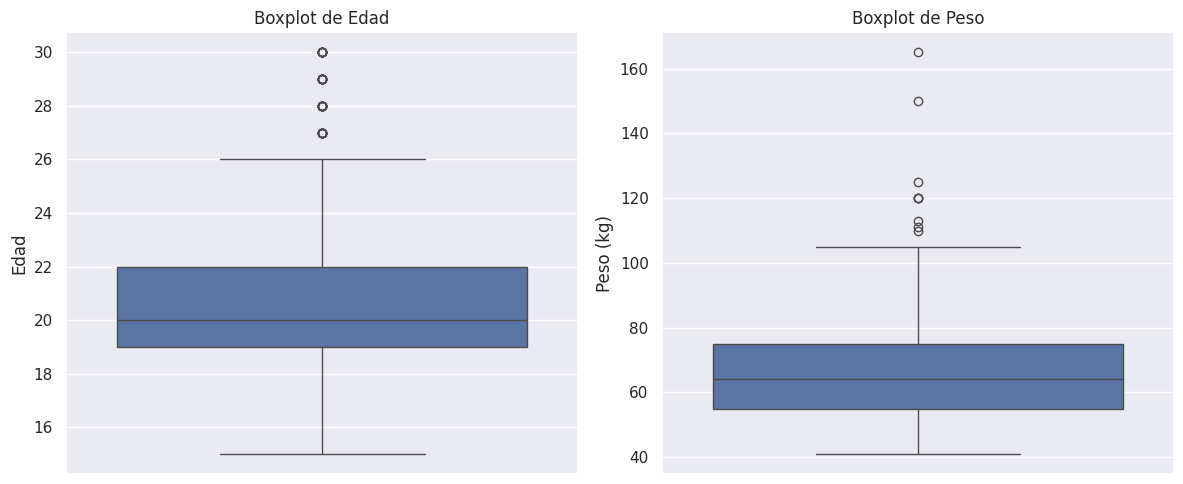

Identificación de Outliers usando el Rango Intercuartílico (IQR):

Outliers en Edad (52):
Age
27.0    14
28.0    17
29.0    11
30.0    10
Name: count, dtype: int64

Outliers en Peso (9):
Weight
110.0    1
111.0    1
113.0    1
120.0    3
125.0    1
150.0    1
165.0    1
Name: count, dtype: int64


In [12]:
print('Identificación de Outliers (Valores Atípicos):')

# Boxplot para la edad
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.boxplot(y=young['Age'].dropna())
plt.title('Boxplot de Edad')
plt.ylabel('Edad')

# Boxplot para el peso
plt.subplot(1, 2, 2)
sns.boxplot(y=young['Weight'].dropna())
plt.title('Boxplot de Peso')
plt.ylabel('Peso (kg)')

plt.tight_layout()
plt.show()

print('Identificación de Outliers usando el Rango Intercuartílico (IQR):')

def find_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)][column]
    return outliers

# Outliers en Edad
outliers_age = find_outliers_iqr(young.dropna(subset=['Age']), 'Age')
print(f'\nOutliers en Edad ({len(outliers_age)}):\n{outliers_age.value_counts().sort_index()}')

# Outliers en Peso
outliers_weight = find_outliers_iqr(young.dropna(subset=['Weight']), 'Weight')
print(f'\nOutliers en Peso ({len(outliers_weight)}):\n{outliers_weight.value_counts().sort_index()}')

### Desglose por Género

Análisis de Edad y Peso por Género:

Estadísticas descriptivas de Edad y Peso por Género:


Age                                                    Weight  \
        count       mean       std   min   25%   50%   75%   max  count   
Gender                                                                    
female  589.0  20.113752  2.792537  15.0  18.0  20.0  21.0  30.0  580.0   
male    409.0  20.872861  2.796789  15.0  19.0  20.0  22.0  30.0  405.0   

                                                             
             mean        std   min   25%   50%   75%    max  
Gender                                                       
female  58.963793  10.005719  41.0  53.0  57.0  63.0  165.0  
male    77.088889  11.349838  53.0  70.0  77.0  83.0  150.0


Comparación Gráfica de Distribuciones por Género:


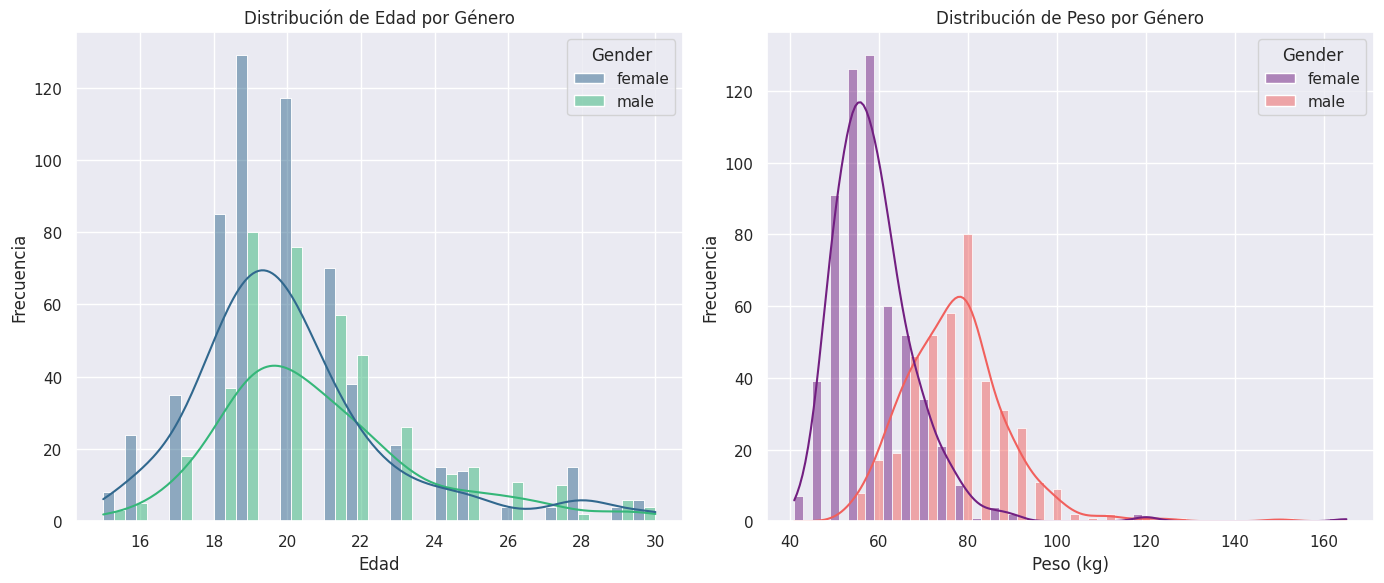

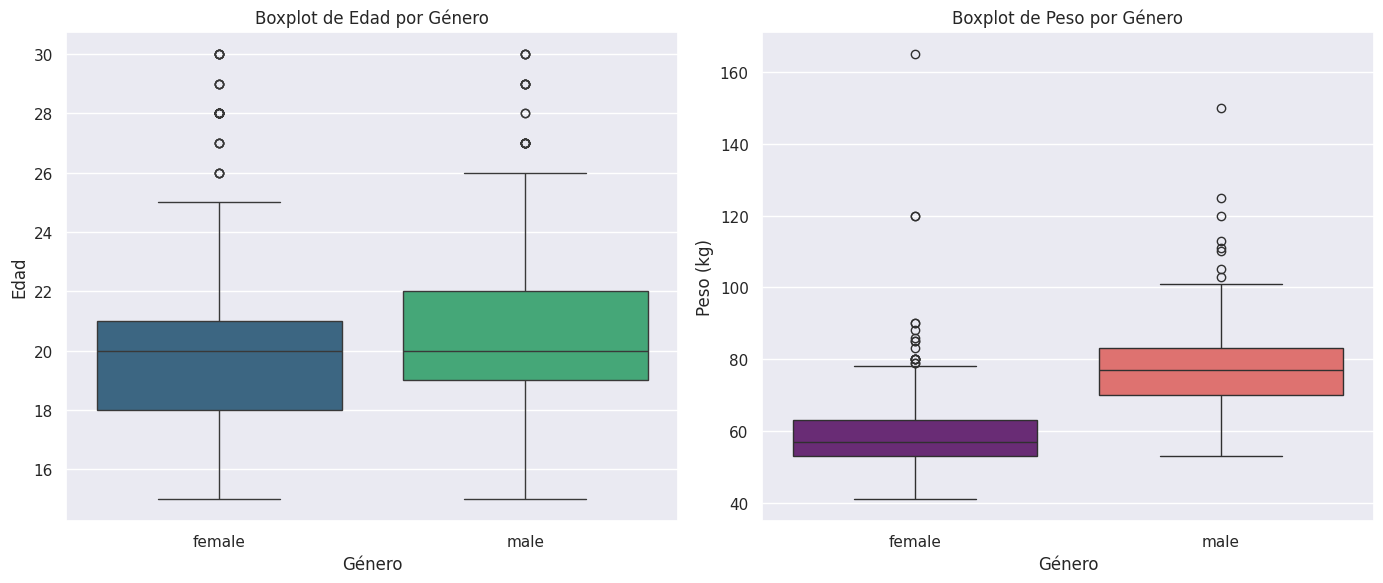

In [13]:
print('Análisis de Edad y Peso por Género:')

# 1. Estadísticas descriptivas por género
print('\nEstadísticas descriptivas de Edad y Peso por Género:')
display(young.groupby('Gender')[['Age', 'Weight']].describe())

# 2. Comparación cualitativa y gráfica de distribuciones por género
print('\nComparación Gráfica de Distribuciones por Género:')

# Histogramas de Edad por Género
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
sns.histplot(data=young, x='Age', hue='Gender', kde=True, palette='viridis', multiple='dodge')
plt.title('Distribución de Edad por Género')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')

# Histogramas de Peso por Género
plt.subplot(1, 2, 2)
sns.histplot(data=young, x='Weight', hue='Gender', kde=True, palette='magma', multiple='dodge')
plt.title('Distribución de Peso por Género')
plt.xlabel('Peso (kg)')
plt.ylabel('Frecuencia')

plt.tight_layout()
plt.show()

# Boxplots de Edad por Género
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
sns.boxplot(data=young, x='Gender', y='Age', palette='viridis')
plt.title('Boxplot de Edad por Género')
plt.xlabel('Género')
plt.ylabel('Edad')

# Boxplots de Peso por Género
plt.subplot(1, 2, 2)
sns.boxplot(data=young, x='Gender', y='Weight', palette='magma')
plt.title('Boxplot de Peso por Género')
plt.xlabel('Género')
plt.ylabel('Peso (kg)')

plt.tight_layout()
plt.show()

### Correlación entre Variables

Correlación entre Variables:

Correlación de Pearson entre Edad y Peso:


,Age,Weight
Age,1.000000,0.237722
Weight,0.237722,1.000000


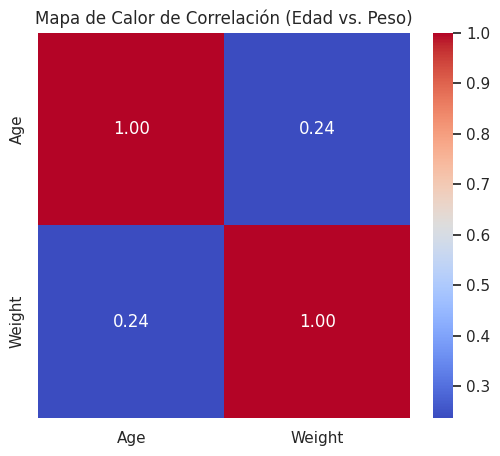

In [14]:
print('Correlación entre Variables:')

# Calcular la correlación de Pearson entre 'Age' y 'Weight'
# Primero, asegurémonos de que no haya valores nulos para el cálculo preciso.
correlation_age_weight = young[['Age', 'Weight']].corr(method='pearson')
print('\nCorrelación de Pearson entre Edad y Peso:')
display(correlation_age_weight)

# Visualización de la correlación de Pearson (heatmap)
plt.figure(figsize=(6, 5))
sns.heatmap(correlation_age_weight, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Mapa de Calor de Correlación (Edad vs. Peso)')
plt.show()

****
## 2. Probabilidad Conjunta

In [15]:
# Identificamos las columnas de 'Smoking' y 'Alcohol'
smoking_col = 'Smoking'
alcohol_col = 'Alcohol'

# Calculamos la probabilidad marginal para 'Smoking'
marginal_smoking = young[smoking_col].value_counts(normalize=True)
print(f"Probabilidad Marginal de {smoking_col}:\n{marginal_smoking}\n")

# Calculamos la probabilidad marginal para 'Alcohol'
marginal_alcohol = young[alcohol_col].value_counts(normalize=True)
print(f"Probabilidad Marginal de {alcohol_col}:\n{marginal_alcohol}")

Probabilidad Marginal de Smoking:
Smoking
tried smoking     0.429142
never smoked      0.207585
current smoker    0.188623
former smoker     0.174651
Name: proportion, dtype: float64

Probabilidad Marginal de Alcohol:
Alcohol
social drinker    0.655721
drink a lot       0.220896
never             0.123383
Name: proportion, dtype: float64


In [16]:
# Calculamos la tabla de contingencia y la normalizamos para obtener probabilidades conjuntas
joint_probability_table = pd.crosstab(young[smoking_col], young[alcohol_col], normalize=True)
print(f"Probabilidad Conjunta de {smoking_col} y {alcohol_col}:\n")
display(joint_probability_table)

Probabilidad Conjunta de Smoking y Alcohol:



Alcohol,drink a lot,never,social drinker
Smoking,,,
current smoker,0.078,0.011,0.099
former smoker,0.055,0.011,0.109
never smoked,0.015,0.061,0.131
tried smoking,0.072,0.039,0.319


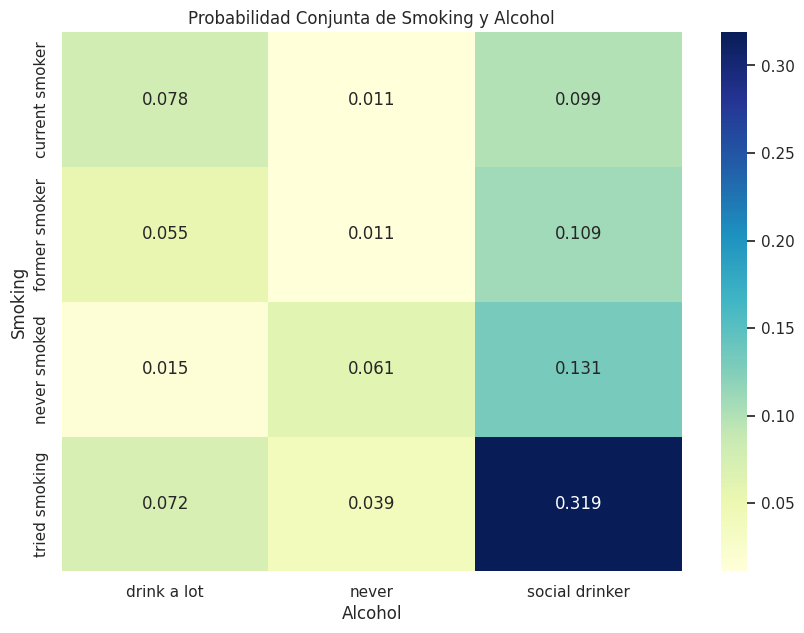

In [17]:
plt.figure(figsize=(10, 7))
sns.heatmap(joint_probability_table, annot=True, fmt='.3f', cmap='YlGnBu')
plt.title(f'Probabilidad Conjunta de {smoking_col} y {alcohol_col}')
plt.xlabel(alcohol_col)
plt.ylabel(smoking_col)
plt.show()

In [18]:
# Definir mapeos para convertir las categorías a valores numéricos
smoking_mapping = {
    'never smoked': 0,
    'tried smoking': 1,
    'former smoker': 2,
    'current smoker': 3
}
alcohol_mapping = {
    'never': 0,
    'social drinker': 1,
    'drink a lot': 2
}

# Crear copias de las columnas y aplicar los mapeos
young_numeric = young.copy()
young_numeric['Smoking_numeric'] = young[smoking_col].map(smoking_mapping)
young_numeric['Alcohol_numeric'] = young[alcohol_col].map(alcohol_mapping)

# Calcular la correlación entre las versiones numéricas (usando Spearman para variables ordinales)
correlation = young_numeric[['Smoking_numeric', 'Alcohol_numeric']].corr(method='spearman')
print(f"Correlación (Spearman) entre {smoking_col} y {alcohol_col}:\n")
display(correlation)

Correlación (Spearman) entre Smoking y Alcohol:



,Smoking_numeric,Alcohol_numeric
Smoking_numeric,1.000000,0.334478
Alcohol_numeric,0.334478,1.000000
